<center>

# 🎮 **Player Segmentation Analysis**

### Clustering and Player Segmentation

---

**Author:** Nelson Nicolás Hernández Becerra  
**Project Type:** Product Analytics & Customer Segmentation  
**Tech Stack:** Python, Pandas, Scikit-Learn, SciPy, Matplotlib, Seaborn

</center>

# 📖 **Notebook Overview**

After completing the feature engineering process, the dataset is now ready for segmentation.

The objective of this notebook is to identify meaningful player groups using clustering techniques and translate the resulting segments into actionable business insights.

The analysis focuses on uncovering differences in player engagement, monetization behavior, and social activity in order to better understand the structure of the player base.

# <font color='green'>📊 **Step 5. Player Segmentation**</font>

In this stage, we apply unsupervised learning techniques to identify groups of players with similar behavioral characteristics.

The goal is to discover underlying patterns within the player base and build interpretable player segments that can support product, marketing, and monetization strategies.

## <font color='green'>🟢 **5.1 Load the Analytical Datasets**</font>

Two datasets generated in the feature engineering stage are loaded:

- `segmentation_dataset.csv` (`X`): the three standardized features used to build the segments, which represent engagement, social activity, and spending.
- `profiling_dataset.csv` (`profile`): the same records, in the same order, in their original units and with additional variables. These variables are used only to describe the segments, never to build them.

Both datasets keep the same row order, which allows the segment labels to be attached to the profiling data later.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

RANDOM_STATE = 42

PROCESSED_PATH = Path("../data/processed")

X = pd.read_csv(PROCESSED_PATH / "segmentation_dataset.csv")
profile = pd.read_csv(PROCESSED_PATH / "profiling_dataset.csv")

assert len(X) == len(profile), "Datasets have a different number of rows"

print("✅ Analytical datasets loaded successfully.")
print("Segmentation features:", X.shape)
print("Profiling dataset:    ", profile.shape)

X.head()

✅ Analytical datasets loaded successfully.
Segmentation features: (2000, 3)
Profiling dataset:     (2000, 12)


,engagement_score_balanced,social_score,Purchase Amount
0,1.166929,-0.860152,0.241280
1,-0.421760,-0.480157,1.355506
2,0.638184,-0.904858,0.376685
3,0.534731,0.637475,-0.590252
4,-0.689000,-0.703684,-0.433199


## <font color='green'>🟢 **5.2 Determining the Number of Clusters**</font>

K-Means requires the number of clusters to be defined in advance. Since the feature set changed during the feature engineering stage, the number of clusters is evaluated again using two complementary criteria:

- **Elbow method (WCSS):** measures how compact the clusters are. WCSS always decreases as K increases, so we look for the point where adding clusters stops producing a meaningful improvement.
- **Silhouette score:** measures how well each record fits its own cluster compared to the nearest alternative. Values closer to 1 indicate better-separated clusters.

Both criteria are calculated for K from 1 to 10 (the silhouette score is undefined for K = 1).

In [2]:
results = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X)

    results.append({
        "k": k,
        "wcss": model.inertia_,
        "silhouette": silhouette_score(X, labels) if k > 1 else np.nan
    })

k_selection = pd.DataFrame(results).set_index("k").round(3)

k_selection

,wcss,silhouette
k,,
1,6000.000,NaN
2,4447.961,0.525
3,3146.166,0.364
4,2288.852,0.361
5,1918.331,0.323
6,1711.176,0.308
7,1562.411,0.303
8,1431.574,0.296
9,1307.785,0.298


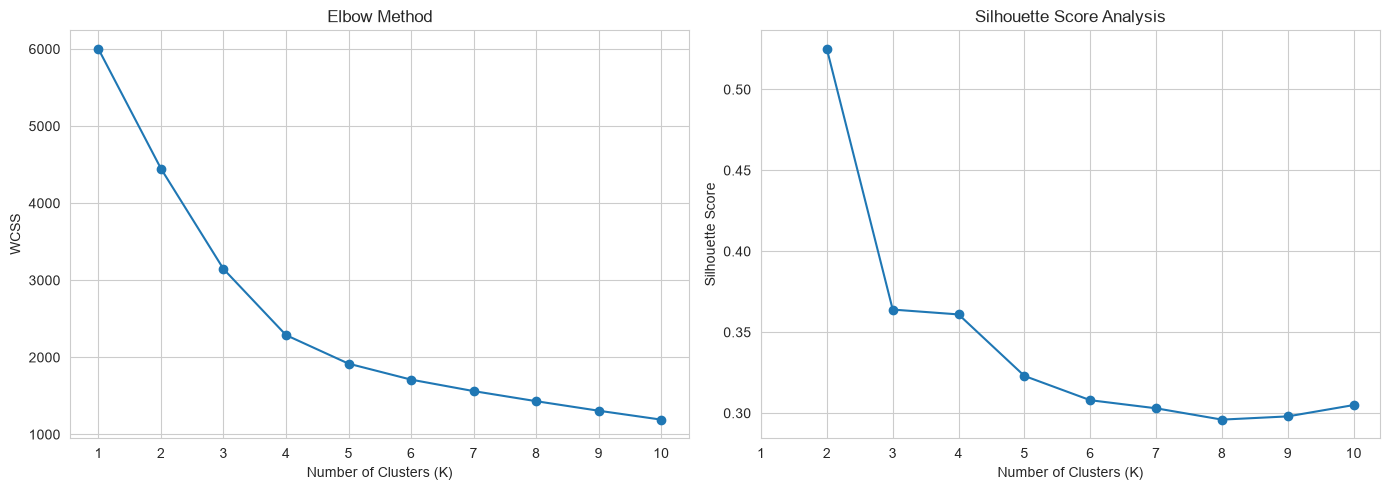

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_selection.index, k_selection["wcss"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("WCSS")

axes[1].plot(k_selection.index[1:], k_selection["silhouette"].iloc[1:], marker="o")
axes[1].set_title("Silhouette Score Analysis")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

for ax in axes:
    ax.set_xticks(list(k_selection.index))

plt.tight_layout()
plt.show()

The two criteria do not point to the same number of clusters:

- The **silhouette score** is highest at K = 2 (**0.525**) and drops sharply at K = 3 (**0.364**), staying almost unchanged at K = 4 (**0.361**). From K = 5 onwards it stays around 0.30 (0.323 or below) without improving.
- The **elbow curve** shows a clear bend at K = 4: the reduction in WCSS is large up to K = 4 (from 3,146 to 2,289, a drop of 857) and much smaller afterwards (from 2,289 to 1,918, a drop of 371). With four clusters, 61.9% of the total variance is explained.

Two additional observations:

- A silhouette of 0.525 at K = 2 can reflect a split along a single dimension, which would be a trivial segmentation. Whether this is the case is checked by comparing the profiles of the candidate solutions.
- For K ≥ 3 the silhouette is approximately between 0.30 and 0.36, which according to a common rule of thumb (Kaufman and Rousseeuw) indicates weak cluster structure. The segments are therefore expected to be partially overlapping groups rather than sharply separated ones.

Based on both criteria, K = 2, 3, and 4 are kept as candidates. The final choice is made after comparing their profiles.

### <font color='green'>**5.2.1 Comparison of Candidate Solutions**</font>

To choose between K = 2, 3, and 4, the clusters of each solution are compared by size and by their average value in each segmentation feature. The values are expressed in standardized units, where 0 is the dataset average and each unit is one standard deviation.

Three aspects are reviewed: whether any cluster is too small to be useful, whether the clusters differ along one dimension or several, and whether increasing K produces groups with a distinct and interpretable profile.

In [4]:
candidate_ks = [2, 3, 4]
comparison = []

for k in candidate_ks:
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X)

    summary = X.groupby(labels).mean().round(2)
    summary.insert(0, "records", pd.Series(labels).value_counts().sort_index())
    summary.insert(1, "share_%", (summary["records"] / len(X) * 100).round(1))
    summary.insert(0, "k", k)

    comparison.append(summary.rename_axis("cluster").reset_index())

k_comparison = pd.concat(comparison).set_index(["k", "cluster"])

k_comparison

records  share_%  engagement_score_balanced  social_score  \
k cluster                                                              
2 0            155      7.8                       0.10          0.22   
  1           1845     92.2                      -0.01         -0.02   
3 0           1250     62.5                      -0.42         -0.43   
  1            145      7.2                       0.07          0.19   
  2            605     30.2                       0.86          0.83   
4 0            481     24.0                       1.20         -0.21   
  1            348     17.4                      -0.03          1.61   
  2            142      7.1                       0.07          0.18   
  3           1029     51.4                      -0.56         -0.47   

           Purchase Amount  
k cluster                   
2 0                   3.03  
  1                  -0.25  
3 0                  -0.25  
  1                   3.13  
  2                  -0.24  
4 0                  -0.26  
  1                  -0.20  
  2                   3.16  
  3                  -0.24

The comparison shows the following:

- **K = 2** is a trivial solution. One cluster (7.8% of records) is separated only by spending (+3.03 standard deviations), while engagement and social activity barely differ from the rest. The high silhouette score of this solution reflects the isolation of the highest spenders and not two distinct player types.
- **K = 3** keeps the high-spending group (7.2%) and divides the remaining records into a low-activity group (62.5%) and a high-activity group (30.2%) in which engagement and social activity increase together.
- **K = 4** splits that high-activity group into an **engagement-led** group (24.0%: engagement +1.20, social -0.21) and a **social-led** group (17.4%: social +1.61, engagement -0.03), while the low-activity group (51.4%) and the high-spending group (7.1%) remain.

The high-spending group is stable across the three solutions, with the same size (7% to 8%) and the same profile: very high spending and average engagement and social activity.

### <font color='green'>**5.2.2 Selected Number of Clusters**</font>

**K = 4 is selected**, for the following reasons:

- The elbow curve shows its clearest bend at K = 4, and its silhouette score (0.361) is practically equal to that of K = 3 (0.364).
- It separates two behaviors that K = 3 groups together, engagement-led and social-led activity, which is consistent with the weak correlation between both variables (0.12).
- All clusters are large enough to be interpreted (the smallest has 142 records, 7.1%).

**Limitations:** the silhouette score of 0.361 indicates weak cluster structure, so the segments should be read as groups with different dominant behaviors rather than as sharply separated categories. In addition, among the three clusters that are not high spenders, `Purchase Amount` is similar, so the monetization dimension essentially distinguishes the upper tail of spending. Both points are taken into account in the segment profiling and in the limitations of this analysis.

## <font color='green'>🟢 **5.3 K-Means Clustering**</font>

### <font color='green'>**5.3.1 Training the Final Model**</font>

The final model is trained with K = 4. The cluster labels are stored separately from the feature dataset `X`, so that the features used to build the segments are never modified.



In [5]:
K_FINAL = 4

final_model = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
labels_final = final_model.fit_predict(X)

segments = pd.Series(labels_final, name="cluster")

segments.value_counts().sort_index()

cluster
0     481
1     348
2     142
3    1029
Name: count, dtype: int64

### <font color='green'>**5.3.2 Stability Check**</font>

Since K-Means starts from random positions, the stability of the solution is verified by training the same model with 20 different random seeds and comparing each resulting grouping with the final one using the **Adjusted Rand Index (ARI)**. An ARI of 1 means identical groupings, while values close to 0 indicate agreement no better than chance.

In [6]:
ari_scores = []

for seed in range(20):
    labels_seed = KMeans(n_clusters=K_FINAL, random_state=seed, n_init=10).fit_predict(X)
    ari_scores.append(adjusted_rand_score(labels_final, labels_seed))

pd.Series(ari_scores, name="ARI").describe().round(3)

count    20.000
mean      0.988
std       0.021
min       0.942
25%       0.987
50%       1.000
75%       1.000
max       1.000
Name: ARI, dtype: float64

The final model produces four clusters of 481, 348, 142, and 1,029 records, identical to the sizes observed in the comparison of candidate solutions.

The stability check shows that the solution is highly stable: across 20 different random seeds, the mean ARI is **0.988**, the median is **1.000**, and the minimum is **0.942**. In most runs the grouping is identical to the final one, and even the least similar run assigns almost every record to the same group. The segments are therefore not an artifact of the random initialization.

Stability does not imply strong separation: the silhouette score (0.361) still indicates partially overlapping groups.

## <font color='green'>🟢 **5.4 Segment Profiling**</font>

The segments are described using the profiling dataset, which keeps the original units of each variable. This allows the segments to be interpreted in business terms (percentage of payers, spending, playtime) instead of standardized units.



### <font color='green'>**5.4.1 Segment Summary**</font>

For each segment, the following indicators are calculated:

- **Size:** number of records and share of the dataset.
- **Monetization:** percentage of payers, average spending per record (including non-payers, who count as zero), and share of the total revenue of the dataset.
- **Behavior:** median `Time Played`, `Level`, `Avg Daily Login`, and `social_score`. Medians are used because these variables are strongly skewed, and averages would be distorted by a small number of extreme values.

In [7]:
profile["cluster"] = segments

segment_summary = profile.groupby("cluster").agg(
    records=("record_id", "count"),
    payer_rate_pct=("is_payer", lambda s: s.mean() * 100),
    avg_spend=("Purchase Amount", "mean"),
    total_spend=("Purchase Amount", "sum"),
    median_time_played=("Time Played", "median"),
    median_level=("Level", "median"),
    median_daily_login=("Avg Daily Login", "median"),
    median_social_score=("social_score", "median"),
)

segment_summary.insert(
    1, "share_%", segment_summary["records"] / len(profile) * 100
)
segment_summary["revenue_share_%"] = (
    segment_summary["total_spend"] / segment_summary["total_spend"].sum() * 100
)

segment_summary = segment_summary.drop(columns="total_spend").round(1)

segment_summary.T

cluster,0,1,2,3
records,481.0,348.0,142.0,1029.0
share_%,24.0,17.4,7.1,51.4
payer_rate_pct,56.1,59.2,100.0,60.8
avg_spend,8.4,9.9,89.0,8.9
median_time_played,12239.0,2592.0,3739.0,800.0
median_level,138.0,69.5,61.5,35.0
median_daily_login,21.0,10.0,9.0,6.0
median_social_score,39.0,117.0,49.0,29.0
revenue_share_%,13.8,11.7,43.3,31.2


The segment summary shows the following:

- **Cluster 2 (high spenders)** contains only **7.1%** of the records but generates **43.3%** of the total revenue. Its average spending per record (89.0) is roughly nine to eleven times that of the other segments (between 8.4 and 9.9). All its records are payers, which is expected since the segment is defined by high spending.
- **The payer rate is similar across the other three segments** (56.1%, 59.2%, and 60.8%), even though their activity levels are very different. Being more engaged or more social does not translate into a higher likelihood of paying, which is consistent with the weak correlations found in the initial hypotheses check.
- **Cluster 0 (engagement-led, 24.0%)** has the highest progression and activity: median `Level` of 138, median `Time Played` of 12,239, and median `Avg Daily Login` of 21. Its median `social_score` is low (39).
- **Cluster 1 (social-led, 17.4%)** has the highest social activity (median `social_score` of 117) with moderate engagement (median `Level` of 69.5).
- **Cluster 3 (low activity, 51.4%)** has the lowest values in every behavioral indicator, but still contributes **31.2%** of the revenue because of its size, with a spending per record (8.9) similar to the active segments.

The median `Time Played` of cluster 3 is 800, which is exactly the minimum value of the variable. This indicates that at least half of this segment sits at the lower bound identified in the data quality assessment, and it is examined in the next section.

### <font color='green'>**5.4.2 Boundary Values by Segment**</font>

In the data quality assessment, several variables were found to concentrate a large share of their records at their lower bound. As documented in the decision of section 2.4.3, these values were retained as observed values, with the commitment of reviewing in the segmentation stage whether any segment is defined only by this concentration.

For the three components of the engagement feature, we calculate the share of records of each segment that sit exactly at the minimum of the variable, and for `Avg Daily Login` also at its maximum. The last column shows the share for the whole dataset as a reference.

In [8]:
floor_cols = ["Time Played", "Level", "Avg Daily Login"]

flags = (profile[floor_cols] == profile[floor_cols].min()).add_suffix(" at min")
flags["Avg Daily Login at max"] = (
    profile["Avg Daily Login"] == profile["Avg Daily Login"].max()
)

floor_by_segment = flags.groupby(profile["cluster"]).mean().mul(100).round(1)
floor_by_segment.loc["All records"] = (flags.mean() * 100).round(1)

floor_by_segment.T

cluster,0,1,2,3,All records
Time Played at min,24.3,44.0,43.7,55.1,45.0
Level at min,18.9,31.3,33.8,42.4,34.2
Avg Daily Login at min,12.7,19.8,23.2,31.2,24.2
Avg Daily Login at max,37.4,22.1,19.7,7.1,17.9


Values at the variable bounds appear in every segment, but their concentration differs:

- **Cluster 3 (low activity)** has the highest share of records at the minimum: **55.1%** in `Time Played`, **42.4%** in `Level`, and **31.2%** in `Avg Daily Login`, compared to 45.0%, 34.2%, and 24.2% in the whole dataset. Even so, 44.9% of its records are above the `Time Played` minimum, so the segment is not defined exclusively by this concentration.
- **Cluster 0 (engagement-led)** has the lowest share at the minimum (24.3% in `Time Played`) and the highest share at the maximum of `Avg Daily Login` (**37.4%**, compared to 17.9% overall).

This shows that the engagement dimension is partly shaped by values accumulated at the bounds of its components: the low-activity segment gathers more records at the floors, and the engagement-led segment gathers more at the login cap. The dataset does not allow us to determine whether these bounds reflect real behavior or limits of the measurement. For this reason, the low-activity and engagement-led segments should be interpreted as groups with comparatively low and high activity, respectively, rather than as exact measures of behavior.

### <font color='green'>**5.4.3 Association with Variables Not Used in the Segmentation**</font>

The segments were built using only engagement, social activity, and spending. To evaluate whether they also differ in other characteristics, we measure the association between the segment and each categorical variable that was not used to build them: `Device Type`, `Facebook Connect Status`, `Social Engagement through Facebook`, and `Specific Action Usage`.

Two indicators are reported for each variable:

- **Cramér's V:** the strength of the association, from 0 (no relationship) to 1 (perfect relationship). As a reference, values below 0.10 are considered negligible, between 0.10 and 0.30 weak, and between 0.30 and 0.50 moderate.
- **p-value of the chi-square test:** the probability of observing an association this strong if there were no relationship at all. With 2,000 records, even very small differences can be statistically significant, so the strength (Cramér's V) is the main indicator.

In [9]:
categorical_cols = [
    "Device Type",
    "Facebook Connect Status",
    "Social Engagement through Facebook",
    "Specific Action Usage"
]

rows = []

for col in categorical_cols:
    table = pd.crosstab(profile["cluster"], profile[col])
    chi2, p, dof, _ = chi2_contingency(table)
    n_obs = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n_obs * (min(table.shape) - 1)))
    rows.append({"variable": col, "cramers_v": v, "p_value": p})

association = pd.DataFrame(rows).set_index("variable").round(
    {"cramers_v": 3, "p_value": 4}
)

association

,cramers_v,p_value
variable,,
Device Type,0.052,0.1898
Facebook Connect Status,0.026,0.7086
Social Engagement through Facebook,0.033,0.6200
Specific Action Usage,0.072,0.6869


The association is negligible for all four variables, with Cramér's V values below 0.10 and no statistically significant relationship (all p-values above 0.18):

- `Device Type`: V = 0.052 (p = 0.190)
- `Facebook Connect Status`: V = 0.026 (p = 0.709)
- `Social Engagement through Facebook`: V = 0.033 (p = 0.620)
- `Specific Action Usage`: V = 0.072 (p = 0.687)

The segments therefore differ in the behaviors used to build them (engagement, social activity, and spending), but not in device type, Facebook connection, or preferred action. This implies that these characteristics cannot be used to identify or target the segments, and that any strategy based on them would have to rely on the behavioral indicators described above.

### <font color='green'>**5.4.4 Reliability Check of the Chi-Square Test**</font>

The chi-square test assumes that the expected counts in the contingency table are not too small. A common rule of thumb is that no more than 20% of the cells should have an expected count below 5.

`Specific Action Usage` has 13 categories and some of them have few records, so we verify this condition for that variable.

In [10]:
table = pd.crosstab(profile["cluster"], profile["Specific Action Usage"])
_, _, _, expected = chi2_contingency(table)

print(f"Table size: {table.shape[0]} segments x {table.shape[1]} categories")
print(f"Cells with expected count below 5: {(expected < 5).mean():.1%}")

Table size: 4 segments x 13 categories
Cells with expected count below 5: 11.5%


Only **11.5%** of the cells have an expected count below 5, which is within the 20% rule of thumb, so the chi-square test can be considered reliable for this variable.

## <font color='green'>🟢 **5.5 Segment Visualization**</font>

The segments are visualized in the space of the three features used to build them. Since there are only three variables, each pair is plotted directly, which keeps the axes interpretable (unlike a dimensionality reduction such as PCA, whose components mix the three variables).

Each point is a record, colored by segment. The diagonal shows the distribution of each feature within each segment. All values are standardized, so 0 is the dataset average and each unit is one standard deviation.

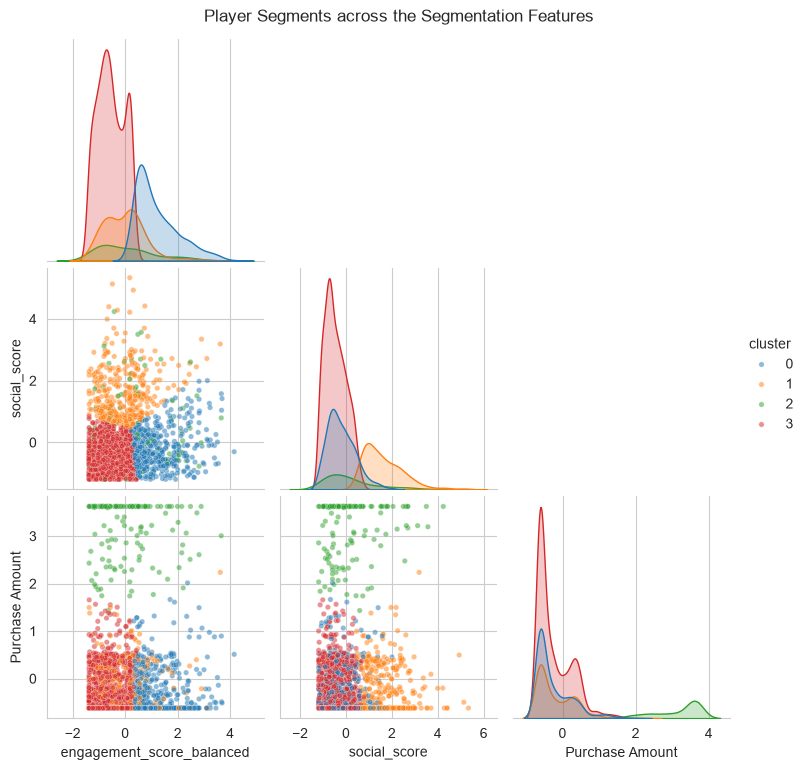

In [11]:
plot_df = X.copy()
plot_df["cluster"] = segments

sns.pairplot(
    plot_df,
    hue="cluster",
    palette="tab10",
    corner=True,
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "s": 15}
)

plt.suptitle("Player Segments across the Segmentation Features", y=1.02)
plt.show()

The visualization shows the following:

- In the engagement–social plane, the segments occupy distinct zones: the social-led segment (cluster 1) in the upper part, the engagement-led segment (cluster 0) on the right, and the low-activity segment (cluster 3) in the dense lower-left block.
- The high-spending segment (cluster 2) is clearly separated along the `Purchase Amount` axis.
- The distribution of engagement within the low-activity segment shows two peaks, which is consistent with the concentration of records at the lower bounds of its components.
- The boundaries between the groups are sharp and there are no empty gaps between them. This is typical when K-Means partitions a continuous cloud of points rather than discovering naturally separated groups, and it is consistent with the weak silhouette score (0.361). The segments should be read as zones of a continuum of behaviors.
- A horizontal line of records appears at the top of the `Purchase Amount` axis, which suggests that many records share the same maximum spending value. This is verified in the next step.

### <font color='green'>**5.5.1 Spending Ceiling Check**</font>

The visualization suggests that many records share the same maximum value of `Purchase Amount`. Since this variable was excluded from the boundary values analysis of the data quality notebook (because of its missing values), we measure here how many records sit exactly at its maximum, by segment.

In [12]:
max_spend = profile["Purchase Amount"].max()
at_max = profile["Purchase Amount"] == max_spend

spend_cap = pd.DataFrame({
    "records_at_max": at_max.groupby(profile["cluster"]).sum(),
    "share_of_segment_%": (at_max.groupby(profile["cluster"]).mean() * 100).round(1)
})
spend_cap.loc["All records"] = [at_max.sum(), round(at_max.mean() * 100, 1)]

print(f"Maximum Purchase Amount: {max_spend}")

spend_cap

Maximum Purchase Amount: 99.99


,records_at_max,share_of_segment_%
cluster,,
0,0.0,0.0
1,0.0,0.0
2,75.0,52.8
3,0.0,0.0
All records,75.0,3.8


The maximum `Purchase Amount` is **99.99**, and it is reached only by records of cluster 2: **75 records, which represent 52.8% of that segment** and 3.8% of the whole dataset. No record of the other segments reaches that value.

This indicates a ceiling in the spending variable. More than half of the high-spending segment sits exactly at the maximum recorded value, so the segment is partly defined by reaching that limit. If the value is a cap, the real spending of these records could be higher, which means the average spending of the segment (89.0) and its share of the revenue (43.3%) could be understated. The dataset does not allow us to verify whether 99.99 is a system limit or a real price.

## <font color='green'>🟢 **5.6 Segment Personas**</font>

The four segments are summarized below. The names are descriptive labels to facilitate communication; they do not imply sharply separated groups.

| Segment | Cluster | Records | Share of revenue | Distinctive profile |
|---|---|---|---|---|
| **High Spenders** | 2 | 142 (7.1%) | 43.3% | All are payers, with an average spending per record of 89.0 (roughly nine to eleven times the other segments). 52.8% of its records sit at the maximum recorded spending (99.99). Average engagement and social activity. |
| **Engaged Progressors** | 0 | 481 (24.0%) | 13.8% | Highest progression and activity: median `Level` of 138, median `Time Played` of 12,239, and median `Avg Daily Login` of 21. Low social activity (median `social_score` of 39). Payer rate of 56.1%. |
| **Social Players** | 1 | 348 (17.4%) | 11.7% | Highest social activity (median `social_score` of 117) with moderate engagement (median `Level` of 69.5). Payer rate of 59.2% and spending per record of 9.9, the highest outside the high spenders. |
| **Casual Players** | 3 | 1,029 (51.4%) | 31.2% | Lowest values in every behavioral indicator (median `Level` of 35, `Avg Daily Login` of 6, and `social_score` of 29), with a median `Time Played` at the minimum value of 800. Payer rate of 60.8% and spending per record of 8.9. |

## <font color='green'>🟢 **5.7 Business Recommendations**</font>

The following recommendations are derived from the segment profiles. They should be treated as hypotheses to be validated through controlled experiments, since the segments describe associations in a single snapshot of the data and do not establish causes.

- **High Spenders (7.1% of records, 43.3% of revenue):** this small group sustains a large part of the revenue, so retaining it is the priority. Possible actions include loyalty programs, early access to new content, and monitoring of changes in their activity as an early warning of churn. Since more than half of them sit at the maximum recorded spending, it would also be valuable to review whether a spending cap limits what these players can buy.
- **Casual Players (51.4% of records, 31.2% of revenue):** their spending per record (8.9) is similar to that of the more active segments, so low activity does not mean low value. Low-cost re-engagement actions, such as reminders and onboarding improvements, are worth testing before investing in more expensive interventions.
- **Engaged Progressors (24.0% of records, 13.8% of revenue):** they have the highest progression but a payer rate (56.1%) and spending per record (8.4) that are not higher than those of other segments. This suggests a monetization opportunity: offers linked to progression milestones could be tested to see whether they increase conversion in this group.
- **Social Players (17.4% of records, 11.7% of revenue):** their social activity is the main distinctive trait. Features that reinforce it, such as friend invitations and guild events, could be tested to see whether they increase their activity and spending.

The segments do not differ in device type, Facebook connection, or preferred action (section 5.4.3), so these characteristics are not useful to target any of these actions.

## <font color='green'>🟢 **5.8 Revisiting the Initial Hypothesis**</font>

The third hypothesis formulated at the beginning of the project stated that distinct player segments exist in the data.

**Status: partially supported.** Four segments with different dominant behaviors were identified, and the solution is stable across random seeds (mean ARI of 0.988). However, the separation between segments is weak (silhouette score of 0.361) and the boundaries between them are not natural gaps, so the segments should be read as zones of a continuum of behaviors rather than as clearly separated types. The high-spending segment is the most clearly differentiated.

## <font color='green'>🟢 **5.9 Limitations**</font>

- **Unit of analysis:** `Player ID` is not a reliable key, so each row is treated as an independent record. The segments describe behavioral profiles of records, not unique individuals.
- **Values at the variable bounds:** several variables concentrate records at their minimum (`Time Played`, `Level`, `Avg Daily Login`), `Avg Daily Login` also at its maximum, and `Purchase Amount` has a ceiling at 99.99 reached by more than half of the high-spending segment. The dataset does not allow us to determine whether these bounds reflect real behavior or limits of the measurement.
- **Weak cluster structure:** the silhouette score (0.361) indicates overlapping groups with sharp boundaries imposed by the algorithm.
- **Engagement composite:** `engagement_score_balanced` averages three variables that are only weakly related to each other, so it represents general activity and not a single behavioral trait.
- **Dataset origin:** the origin of the data could not be verified. The share of payers (62.2%) is unusually high compared with what is commonly reported for mobile games, which suggests that the dataset may be a sample or may have been generated artificially.
- **Static snapshot and model assumptions:** the analysis uses a single snapshot without time dimension, and K-Means is sensitive to extreme values (the standardized features reach up between 3.6 and 5.3 standard deviations) and tends to form compact groups.
- **Social score composition:** `social_score` is a simple sum in which `Guild Chat Messages` has a somewhat larger weight than friend invitations (correlation with the score of 0.75 versus 0.42 and 0.60).
- **Variables not used:** `Attempts`, `Booster Used`, `Level Completion Time`, `Lives from Ads`, and `OS Version` were not included in the segmentation. In particular, ad-based monetization (`Lives from Ads`) is not captured, since monetization is measured only through purchases.
- **Meaning of spending:** each record holds a single recorded purchase amount in an undocumented currency, so "revenue" refers to the sum of recorded amounts, not to the total lifetime spending of a player.

## <font color='green'>🟢 **5.10 Conclusions**</font>

This notebook segmented the player records into four groups using engagement, social activity, and spending:

- The selected solution (K = 4) is stable across random seeds, although its structure is weak.
- A small group of high spenders (7.1% of records) generates 43.3% of the revenue, and more than half of its records sit at the maximum recorded spending.
- The most active segments do not pay more than the casual one: the payer rate is similar across the three segments that are not high spenders (between 56% and 61%), and the casual segment, which represents half of the records, contributes 31.2% of the revenue.
- The segments do not differ in device, Facebook connection, or preferred action.

The results provide a useful descriptive view of the dataset and a set of hypotheses for business actions, with the limitations documented in the previous section. The most valuable next step would be to validate the recommendations through experiments and to repeat the analysis with data that allow tracking the same player over time.